# California Housing Dataset

In [24]:
# Importing Libraries
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score
from sklearn.tree import DecisionTreeRegressor
from sklearn.ensemble import RandomForestRegressor
from sklearn.model_selection import train_test_split, RandomizedSearchCV
from scipy.stats import randint

# Q1 : Loading Dataset

In [25]:
df = pd.read_csv('housing.csv')
df.head()

,longitude,latitude,housing_median_age,total_rooms,total_bedrooms,population,households,median_income,median_house_value
0,-122.23,37.88,41,880,129.0,322,126,8.3252,452600
1,-122.22,37.86,21,7099,1106.0,2401,1138,8.3014,358500
2,-122.24,37.85,52,1467,190.0,496,177,7.2574,352100
3,-122.25,37.85,52,1274,235.0,558,219,5.6431,341300
4,-122.25,37.85,52,1627,280.0,565,259,3.8462,342200


# Q2: EDA

In [26]:
df.shape

(20640, 9)

In [27]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 20640 entries, 0 to 20639
Data columns (total 9 columns):
 #   Column              Non-Null Count  Dtype  
---  ------              --------------  -----  
 0   longitude           20640 non-null  float64
 1   latitude            20640 non-null  float64
 2   housing_median_age  20640 non-null  int64  
 3   total_rooms         20640 non-null  int64  
 4   total_bedrooms      20433 non-null  float64
 5   population          20640 non-null  int64  
 6   households          20640 non-null  int64  
 7   median_income       20640 non-null  float64
 8   median_house_value  20640 non-null  int64  
dtypes: float64(4), int64(5)
memory usage: 1.4 MB


In [28]:
df.describe().transpose()

,count,mean,std,min,25%,50%,75%,max
longitude,20640.0,-119.569704,2.003532,-124.3500,-121.8000,-118.4900,-118.01000,-114.3100
latitude,20640.0,35.631861,2.135952,32.5400,33.9300,34.2600,37.71000,41.9500
housing_median_age,20640.0,28.639486,12.585558,1.0000,18.0000,29.0000,37.00000,52.0000
total_rooms,20640.0,2635.763081,2181.615252,2.0000,1447.7500,2127.0000,3148.00000,39320.0000
total_bedrooms,20433.0,537.870553,421.385070,1.0000,296.0000,435.0000,647.00000,6445.0000
population,20640.0,1425.476744,1132.462122,3.0000,787.0000,1166.0000,1725.00000,35682.0000
households,20640.0,499.539680,382.329753,1.0000,280.0000,409.0000,605.00000,6082.0000
median_income,20640.0,3.870671,1.899822,0.4999,2.5634,3.5348,4.74325,15.0001
median_house_value,20640.0,206855.816909,115395.615874,14999.0000,119600.0000,179700.0000,264725.00000,500001.0000


In [29]:
df.index

RangeIndex(start=0, stop=20640, step=1)

In [30]:
df.columns

Index(['longitude', 'latitude', 'housing_median_age', 'total_rooms',
       'total_bedrooms', 'population', 'households', 'median_income',
       'median_house_value'],
      dtype='object')

# Q3: Data Preparation

In [31]:
df.corr()['median_house_value']

longitude            -0.045967
latitude             -0.144160
housing_median_age    0.105623
total_rooms           0.134153
total_bedrooms        0.049686
population           -0.024650
households            0.065843
median_income         0.688075
median_house_value    1.000000
Name: median_house_value, dtype: float64

<Axes: xlabel='median_income', ylabel='median_house_value'>

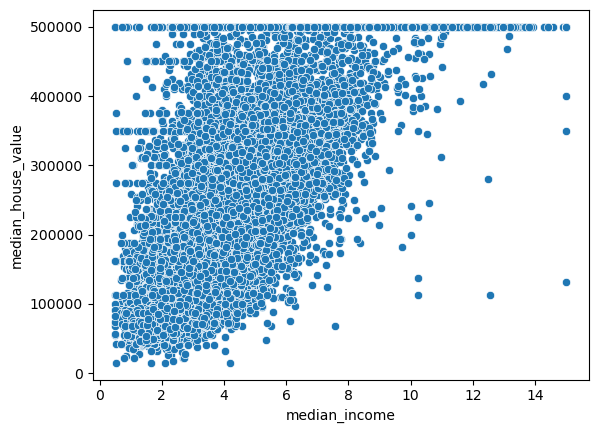

In [32]:
sns.scatterplot(x = 'median_income', y = 'median_house_value',data = df)

In [33]:
def remove_outliers_iqr(df, columns):
    for col in columns:
        Q1 = df[col].quantile(0.25)
        Q3 = df[col].quantile(0.75)
        IQR = Q3 - Q1
        lower = Q1 - 1.5 * IQR
        upper = Q3 + 1.5 * IQR
        df = df[(df[col] >= lower) & (df[col] <= upper)]
    return df

In [34]:
numeric_cols = df.select_dtypes(include='number').columns
df= remove_outliers_iqr(df, numeric_cols)

<Axes: xlabel='median_income', ylabel='median_house_value'>

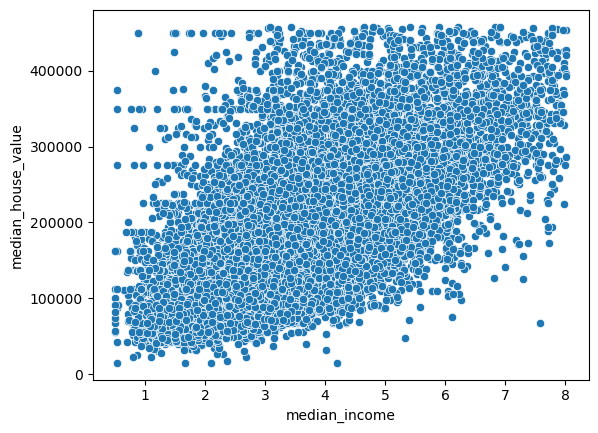

In [35]:
sns.scatterplot(x = 'median_income', y = 'median_house_value',data = df)

In [36]:
df.isnull().sum()

longitude             0
latitude              0
housing_median_age    0
total_rooms           0
total_bedrooms        0
population            0
households            0
median_income         0
median_house_value    0
dtype: int64

# Q4: Data Engineering

In [37]:
# New Features
df["rooms_per_household"] = df["total_rooms"] / df["households"]
df["bedrooms_per_room"] = df["total_bedrooms"] / df["total_rooms"]
df["population_per_household"] = df["population"] / df["households"]

In [38]:
# Correlation between Features and Target
corr_matrix = df.corr(numeric_only=True)
target_corr = corr_matrix["median_house_value"].sort_values(ascending=False)

In [39]:
target_corr

median_house_value          1.000000
median_income               0.635561
total_rooms                 0.200932
households                  0.120938
rooms_per_household         0.093044
housing_median_age          0.090996
total_bedrooms              0.089554
population                 -0.008382
longitude                  -0.037621
latitude                   -0.164187
population_per_household   -0.183443
bedrooms_per_room          -0.212319
Name: median_house_value, dtype: float64

In [40]:
# Identifying Low-importance Features
low_corr_features = target_corr[target_corr.abs() < 0.1].index.tolist()

In [41]:
low_corr_features

['rooms_per_household',
 'housing_median_age',
 'total_bedrooms',
 'population',
 'longitude']

In [45]:
# Removing Features
df = df.drop(columns=low_corr_features, errors="ignore")

### Standardization: 

In [46]:
num_cols = df.select_dtypes(include=["float64", "int64"]).columns
scaler = StandardScaler()
df[num_cols] = scaler.fit_transform(df[num_cols])

In [47]:
df.head()

,latitude,total_rooms,households,median_income,median_house_value,bedrooms_per_room,population_per_household
2,0.981656,-0.590578,-1.195397,2.543685,1.812070,-1.545828,-0.152851
3,0.981656,-0.779033,-0.969518,1.427730,1.694717,-0.546769,-0.400366
4,0.981656,-0.434345,-0.754394,0.185546,1.704496,-0.771566,-0.757045
5,0.981656,-1.125675,-1.109348,0.317306,0.916711,0.313600,-0.797504
6,0.977055,0.452276,0.617019,0.056205,1.237258,-0.393280,-0.808689


### Test & Train

In [48]:
train_set, test_set = train_test_split(df, test_size=0.2, random_state=42)

In [49]:
print("Train set:", train_set.shape)
print("Test set:", test_set.shape)

Train set: (13380, 7)
Test set: (3345, 7)


# Q5: Visualization

### Housing Price Histogram

C:\Users\www.markazi.co\anaconda3\Lib\site-packages\seaborn\_oldcore.py:1119: FutureWarning: use_inf_as_na option is deprecated and will be removed in a future version. Convert inf values to NaN before operating instead.
  with pd.option_context('mode.use_inf_as_na', True):


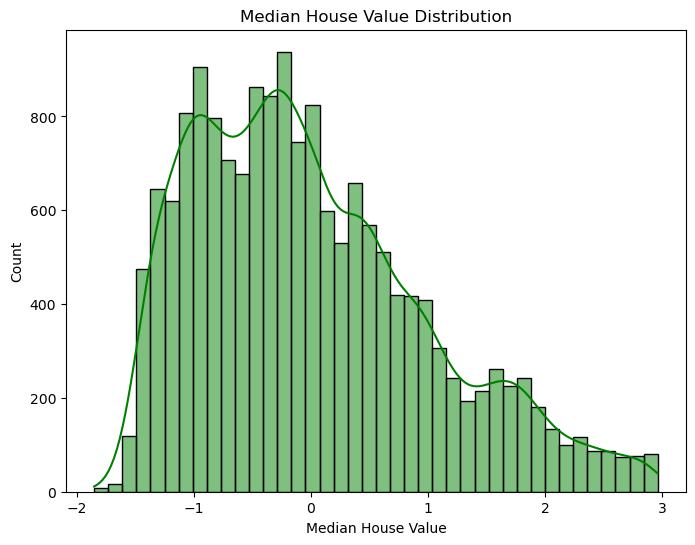

In [54]:
plt.figure(figsize=(8,6))
sns.histplot(df['median_house_value'], bins=40, kde=True, color="green")
plt.title('Median House Value Distribution')
plt.xlabel('Median House Value')
plt.ylabel('Count')
plt.show()

### Features Correlation Heatmap

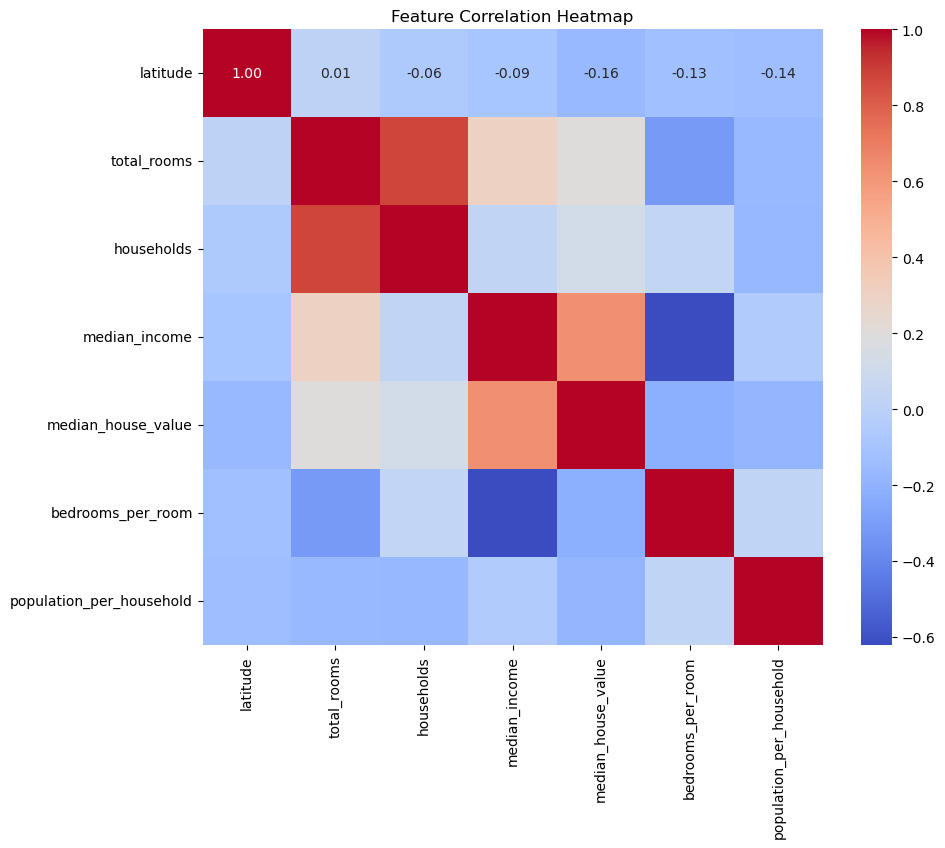

In [56]:
plt.figure(figsize=(10,8))
corr = df.corr(numeric_only=True)
sns.heatmap(corr, annot=True, fmt=".2f", cmap="coolwarm", cbar=True)
plt.title('Feature Correlation Heatmap')
plt.show()

### Scatter Plot

# Q6-Q7: Prediction Models and Evaluation

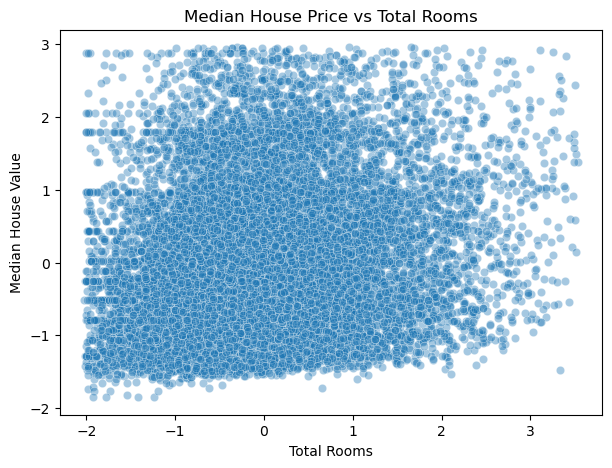

In [65]:
plt.figure(figsize=(7,5))
sns.scatterplot(x="total_rooms", y="median_house_value", data=df, alpha=0.4)
plt.title('Median House Price vs Total Rooms')
plt.xlabel('Total Rooms')
plt.ylabel('Median House Value')
plt.show()

### Linear Regression

In [66]:
X = df.drop("median_house_value", axis=1)
y = df["median_house_value"]

In [67]:
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

In [70]:
lr_model = LinearRegression()
lr_model.fit(X_train, y_train)
y_pred = lr_model.predict(X_test)

In [74]:
rmse_lr = np.sqrt(mean_squared_error(y_test, y_pred))
mae_lr = mean_absolute_error(y_test, y_pred)
r2_lr = r2_score(y_test, y_pred)

In [75]:
print(f"RMSE_lr: {rmse_lr:.2f}")
print(f"MAE_lr: {mae_lr:.2f}")
print(f"R² Score_lr: {r2_lr:.3f}")

RMSE_lr: 0.71
MAE_lr: 0.53
R² Score_lr: 0.484


### Decision Tree Regressor

In [76]:
dt_model = DecisionTreeRegressor(random_state=42)
dt_model.fit(X_train, y_train)
y_pred = dt_model.predict(X_test)

In [77]:
rmse_dt = np.sqrt(mean_squared_error(y_test, y_pred))
mae_dt = mean_absolute_error(y_test, y_pred)
r2_dt = r2_score(y_test, y_pred)

In [78]:
print(f"RMSE_dt: {rmse_dt:.2f}")
print(f"MAE_dt: {mae_dt:.2f}")
print(f"R² Score_dt: {r2_dt:.3f}")

RMSE_dt: 0.82
MAE_dt: 0.57
R² Score_dt: 0.304


### Random Forest Regressor

In [79]:
rf_model = RandomForestRegressor(
    n_estimators=100,        
    max_depth=None,          
    random_state=42,
    n_jobs=-1              
)

rf_model.fit(X_train, y_train)
y_pred = rf_model.predict(X_test)

In [80]:
rmse_rf = np.sqrt(mean_squared_error(y_test, y_pred))
mae_rf = mean_absolute_error(y_test, y_pred)
r2_rf = r2_score(y_test, y_pred)

In [81]:
print(f"RMSE_rf: {rmse_rf:.2f}")
print(f"MAE_rf: {mae_rf:.2f}")
print(f"R² Score_rf: {r2_rf:.3f}")

RMSE_rf: 0.60
MAE_rf: 0.43
R² Score_rf: 0.631


### Comparing Models

In [82]:
models = {
    "Linear Regression": LinearRegression(),
    "Decision Tree": DecisionTreeRegressor(random_state=42),
    "Random Forest": RandomForestRegressor(n_estimators=100, random_state=42)
}

In [83]:
#  آموزش و ارزیابی مدل‌ها
results = []
for name, model in models.items():
    model.fit(X_train, y_train)
    y_pred = model.predict(X_test)
    rmse = np.sqrt(mean_squared_error(y_test, y_pred))
    mae = mean_absolute_error(y_test, y_pred)
    r2 = r2_score(y_test, y_pred)
    results.append({"Model": name, "RMSE": rmse, "MAE": mae, "R²": r2})

In [84]:
results

[{'Model': 'Linear Regression',
  'RMSE': 0.7100787842358727,
  'MAE': 0.5286923218918016,
  'R²': 0.484471620984981},
 {'Model': 'Decision Tree',
  'RMSE': 0.8249312816563733,
  'MAE': 0.5713979606134574,
  'R²': 0.3042150212673267},
 {'Model': 'Random Forest',
  'RMSE': 0.6006056181877796,
  'MAE': 0.4276613626061478,
  'R²': 0.6311767552395542}]

In [85]:
# Comparision Table
results_df = pd.DataFrame(results).sort_values(by="R²", ascending=False)
results_df

,Model,RMSE,MAE,R²
2,Random Forest,0.600606,0.427661,0.631177
0,Linear Regression,0.710079,0.528692,0.484472
1,Decision Tree,0.824931,0.571398,0.304215


In [86]:
# The Best Model Based on R^2
best_model = results_df.iloc[0]["Model"]
print(f"The Best Model: {best_model}")

The Best Model: Random Forest


# Q8: Model Improvement

In [87]:
param_dist = {
    "n_estimators": randint(50, 300),       
    "max_depth": randint(5, 50),           
    "min_samples_split": randint(2, 20),    
    "min_samples_leaf": randint(1, 10),     
    "max_features": ["auto", "sqrt", "log2"]  
}

In [88]:
rf = RandomForestRegressor(random_state=42)
random_search = RandomizedSearchCV(
    rf,
    param_distributions=param_dist,
    n_iter=30,                 
    scoring="r2",             
    cv=3,             
    verbose=2,
    random_state=42,
    n_jobs=-1
)

random_search.fit(X_train, y_train)

Fitting 3 folds for each of 30 candidates, totalling 90 fits


RandomizedSearchCV(cv=3, estimator=RandomForestRegressor(random_state=42),
                   n_iter=30, n_jobs=-1,
                   param_distributions={'max_depth': <scipy.stats._distn_infrastructure.rv_discrete_frozen object at 0x000001F53A69E9D0>,
                                        'max_features': ['auto', 'sqrt',
                                                         'log2'],
                                        'min_samples_leaf': <scipy.stats._distn_infrastructure.rv_discrete_frozen object at 0x000001F53B04B8D0>,
                                        'min_samples_split': <scipy.stats._distn_infrastructure.rv_discrete_frozen object at 0x000001F53B04BD10>,
                                        'n_estimators': <scipy.stats._distn_infrastructure.rv_discrete_frozen object at 0x000001F53B030A90>},
                   random_state=42, scoring='r2', verbose=2)

In [89]:
# Best Parameters
random_search.best_params_

{'max_depth': 48,
 'max_features': 'sqrt',
 'min_samples_leaf': 3,
 'min_samples_split': 2,
 'n_estimators': 276}

In [90]:
# Final Model Evaluation
best_model = random_search.best_estimator_
y_pred = best_model.predict(X_test)

rmse_best = np.sqrt(mean_squared_error(y_test, y_pred))
mae_best = mean_absolute_error(y_test, y_pred)
r2_best = r2_score(y_test, y_pred)

In [91]:
print(f"RMSE_best: {rmse_best:.2f}")
print(f"MAE-best: {mae_best:.2f}")
print(f"R² Score_best: {r2_best:.3f}")

RMSE_best: 0.59
MAE-best: 0.43
R² Score_best: 0.641


In [92]:
results = pd.DataFrame({
    "Model": ['model_base','model_best'],
    "RMSE": [rmse_rf, rmse_best],
    "MAE": [mae_rf, mae_best],
    "R²": [r2_rf, r2_best]
})

results

,Model,RMSE,MAE,R²
0,model_base,0.600606,0.427661,0.631177
1,model_best,0.592919,0.427048,0.640557


# Q9: Data Storytelling

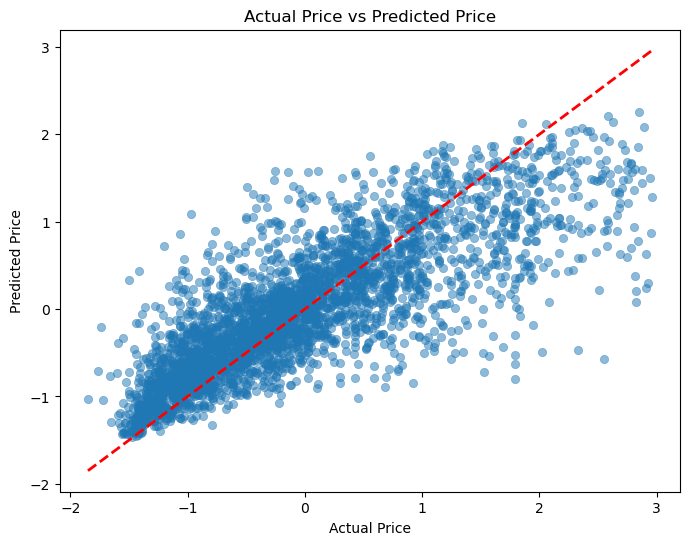

In [93]:
plt.figure(figsize=(8,6))
sns.scatterplot(x=y_test, y=y_pred, alpha=0.5, edgecolor=None)
plt.plot([y_test.min(), y_test.max()], [y_test.min(), y_test.max()], 'r--', lw=2)
plt.xlabel("Actual Price")
plt.ylabel("Predicted Price")
plt.title("Actual Price vs Predicted Price")
plt.show()

In [94]:
importances = pd.Series(best_model.feature_importances_, index=X.columns).sort_values(ascending=False)
print(f'Most important Feature: {importances.head(1)}')

Most important Feature: median_income    0.412161
dtype: float64


### Limitations and Recommendations for Improvement 

1- Gathering more data
2- Including more features such as number of schools, public transport, neughborhood safety
1- Using advanced Algorithms such as 